In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    RandomizedSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
!pip install xgboost

In [4]:
import pandas as pd

# Load both CSV files
df1 = pd.read_csv("labels.csv")
df2 = pd.read_csv("values.csv")

# Check first dataset
print("Dataset 1 Shape:", df1.shape)
display(df1.head())

# Check second dataset
print("Dataset 2 Shape:", df2.shape)
display(df2.head())

Dataset 1 Shape: (180, 2)


,patient_id,heart_disease_present
0,0z64un,0
1,ryoo3j,0
2,yt1s1x,1
3,l2xjde,1
4,oyt4ek,0


Dataset 2 Shape: (180, 14)


,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0


In [5]:
# Merge both datasets using patient_id

df = pd.merge(
    df2,
    df1,
    on='patient_id',
    how='inner',
    validate='one_to_one'
)

# Display merged dataset
print("Merged Dataset Shape:", df.shape)

df.head()

Merged Dataset Shape: (180, 15)


,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


In [6]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("Duplicates:", df.duplicated().sum())

# Check target distribution
print("\nTarget Distribution:")
print(df['heart_disease_present'].value_counts())

Missing Values:
patient_id                              0
slope_of_peak_exercise_st_segment       0
thal                                    0
resting_blood_pressure                  0
chest_pain_type                         0
num_major_vessels                       0
fasting_blood_sugar_gt_120_mg_per_dl    0
resting_ekg_results                     0
serum_cholesterol_mg_per_dl             0
oldpeak_eq_st_depression                0
sex                                     0
age                                     0
max_heart_rate_achieved                 0
exercise_induced_angina                 0
heart_disease_present                   0
dtype: int64
Duplicates: 0

Target Distribution:
heart_disease_present
0    100
1     80
Name: count, dtype: int64


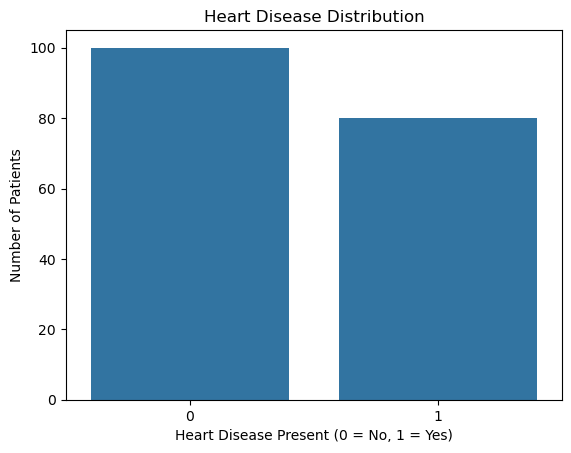

In [7]:
sns.countplot(
    data=df,
    x='heart_disease_present'
)

plt.title('Heart Disease Distribution')
plt.xlabel('Heart Disease Present (0 = No, 1 = Yes)')
plt.ylabel('Number of Patients')
plt.show()

### Data Cleaning

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   patient_id                            180 non-null    object 
 1   slope_of_peak_exercise_st_segment     180 non-null    int64  
 2   thal                                  180 non-null    object 
 3   resting_blood_pressure                180 non-null    int64  
 4   chest_pain_type                       180 non-null    int64  
 5   num_major_vessels                     180 non-null    int64  
 6   fasting_blood_sugar_gt_120_mg_per_dl  180 non-null    int64  
 7   resting_ekg_results                   180 non-null    int64  
 8   serum_cholesterol_mg_per_dl           180 non-null    int64  
 9   oldpeak_eq_st_depression              180 non-null    float64
 10  sex                                   180 non-null    int64  
 11  age                

In [9]:
# Missing values count
missing_values = df.isnull().sum()

print(missing_values)

patient_id                              0
slope_of_peak_exercise_st_segment       0
thal                                    0
resting_blood_pressure                  0
chest_pain_type                         0
num_major_vessels                       0
fasting_blood_sugar_gt_120_mg_per_dl    0
resting_ekg_results                     0
serum_cholesterol_mg_per_dl             0
oldpeak_eq_st_depression                0
sex                                     0
age                                     0
max_heart_rate_achieved                 0
exercise_induced_angina                 0
heart_disease_present                   0
dtype: int64


In [11]:
# Check duplicate records
print("Total Duplicates:", df.duplicated().sum())

Total Duplicates: 0


In [12]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (180, 15)


In [13]:
# Unique values in each column
for col in df.columns:
    print("\nColumn:", col)
    print(df[col].unique())


Column: patient_id
['0z64un' 'ryoo3j' 'yt1s1x' 'l2xjde' 'oyt4ek' 'ldukkw' '2gbyh9' 'daa9kp'
 '3nwy2n' '1r508r' 'ldg4b9' 'xc17yq' 'mpggsq' 'zlyac8' 'f06u72' '2fv3rc'
 'qyrkxn' '237mql' 'mc750a' '30v796' 'cvux3j' 'k8899q' 'jhdvtb' '5g9v0h'
 '83asqd' 'gla0im' 'zzmfh7' 'f4g1ay' 'lek9q9' '8265rl' '6017a1' 'z7xkou'
 'k7ef7h' '0n5fu0' '55xksg' 'pjgqa3' 'xkdz7j' 'tpuevg' 'ascl42' '1xwoe6'
 'ty4ik8' 'gx6yxl' 'hlmts5' 'yx0q6k' 'ep1o51' 'gj1e5z' '6219kl' 'rp9g6x'
 '1aeaff' 'y3prof' '3drd48' 'ejo7p3' 'r7y4i1' 'mznwxv' '27oevk' 'jwqi3k'
 '328lkl' 'tlk9o8' 'aq2vrq' 'ilogfb' 'rv6siv' 'm2a4i9' 'pwigd8' 'qwapdq'
 '4sd1xn' 'nck22c' 'm6zksp' 'f70grj' 'k1art8' 'mcwqgs' '3jsjqk' 'ik7hfs'
 'qwj1yf' 'qvhk9e' 'igwnqo' '4v0q7o' 'hh2awp' 'vfjppl' '6lu42b' 'shiro4'
 '3wl3z4' 'ebioez' '37c0vm' 'v52zcs' '6nkcaw' 'hfp05i' 'grfxwd' 'bvcxah'
 'i49srr' '93dbhq' 'jscmp8' 'zaytyf' 'wze8qm' 'w3933i' '7uch9x' 'dy5hxt'
 'c0gkqc' 'z5g5p3' 'h3uzv8' 'bthqr4' 'rfj25e' '9f92et' '24fopx' 'ldr1mz'
 'wokyol' 'p5orwa' 's8dx1q' '7k

In [14]:
# Numerical columns
numerical_cols = df.select_dtypes(include=np.number).columns

print("Numerical Columns:")
print(numerical_cols.tolist())

Numerical Columns:
['slope_of_peak_exercise_st_segment', 'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels', 'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age', 'max_heart_rate_achieved', 'exercise_induced_angina', 'heart_disease_present']


In [15]:
# Categorical columns
categorical_cols = df.select_dtypes(include='object').columns

print("Categorical Columns:")
print(categorical_cols.tolist())

Categorical Columns:
['patient_id', 'thal']


In [16]:
# Statistical summary
df.describe().T

,count,mean,std,min,25%,50%,75%,max
slope_of_peak_exercise_st_segment,180.0,1.550000,0.618838,1.0,1.00,1.0,2.00,3.0
resting_blood_pressure,180.0,131.311111,17.010443,94.0,120.00,130.0,140.00,180.0
chest_pain_type,180.0,3.155556,0.938454,1.0,3.00,3.0,4.00,4.0
num_major_vessels,180.0,0.694444,0.969347,0.0,0.00,0.0,1.00,3.0
fasting_blood_sugar_gt_120_mg_per_dl,180.0,0.161111,0.368659,0.0,0.00,0.0,0.00,1.0
resting_ekg_results,180.0,1.050000,0.998742,0.0,0.00,2.0,2.00,2.0
serum_cholesterol_mg_per_dl,180.0,249.211111,52.717969,126.0,213.75,245.5,281.25,564.0
oldpeak_eq_st_depression,180.0,1.010000,1.121357,0.0,0.00,0.8,1.60,6.2
sex,180.0,0.688889,0.464239,0.0,0.00,1.0,1.00,1.0
age,180.0,54.811111,9.334737,29.0,48.00,55.0,62.00,77.0


In [17]:
# Check negative values in numerical columns
for col in numerical_cols:
    print(col, ":", (df[col] < 0).sum())

slope_of_peak_exercise_st_segment : 0
resting_blood_pressure : 0
chest_pain_type : 0
num_major_vessels : 0
fasting_blood_sugar_gt_120_mg_per_dl : 0
resting_ekg_results : 0
serum_cholesterol_mg_per_dl : 0
oldpeak_eq_st_depression : 0
sex : 0
age : 0
max_heart_rate_achieved : 0
exercise_induced_angina : 0
heart_disease_present : 0


In [18]:
print("FINAL DATA CLEANING REPORT")

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("\nData Cleaning Completed!")

FINAL DATA CLEANING REPORT
Total Rows: 180
Total Columns: 15
Missing Values: 0
Duplicate Rows: 0

Data Cleaning Completed!


### Exploratory Data Analysis (EDA)

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11

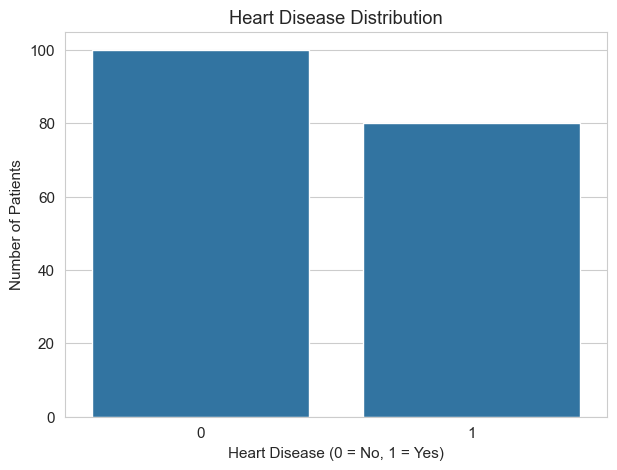

In [20]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x='heart_disease_present'
)

plt.title('Heart Disease Distribution')
plt.xlabel('Heart Disease (0 = No, 1 = Yes)')
plt.ylabel('Number of Patients')

plt.show()

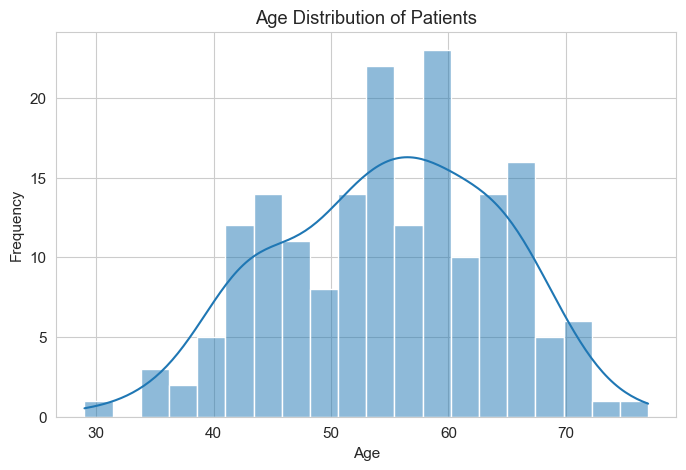

In [21]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='age',
    bins=20,
    kde=True
)

plt.title('Age Distribution of Patients')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

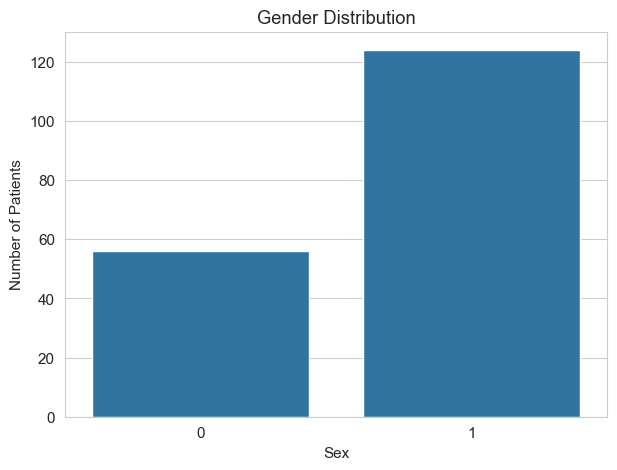

In [22]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x='sex'
)

plt.title('Gender Distribution')
plt.xlabel('Sex')
plt.ylabel('Number of Patients')

plt.show()

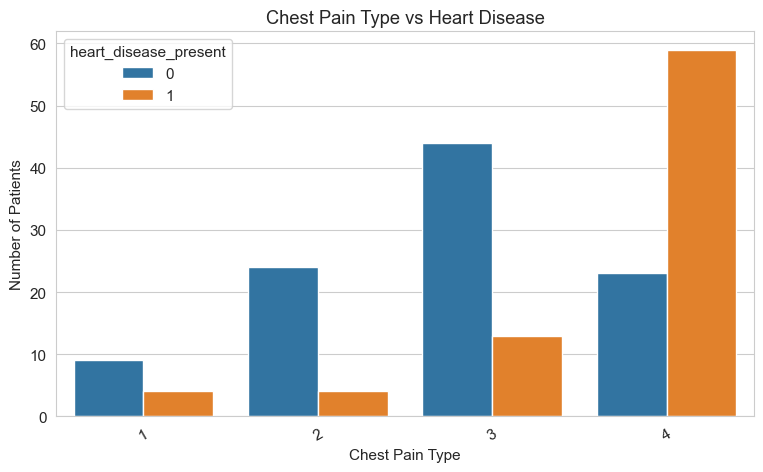

In [23]:
plt.figure(figsize=(9,5))

sns.countplot(
    data=df,
    x='chest_pain_type',
    hue='heart_disease_present'
)

plt.title('Chest Pain Type vs Heart Disease')
plt.xlabel('Chest Pain Type')
plt.ylabel('Number of Patients')

plt.xticks(rotation=30)
plt.show()

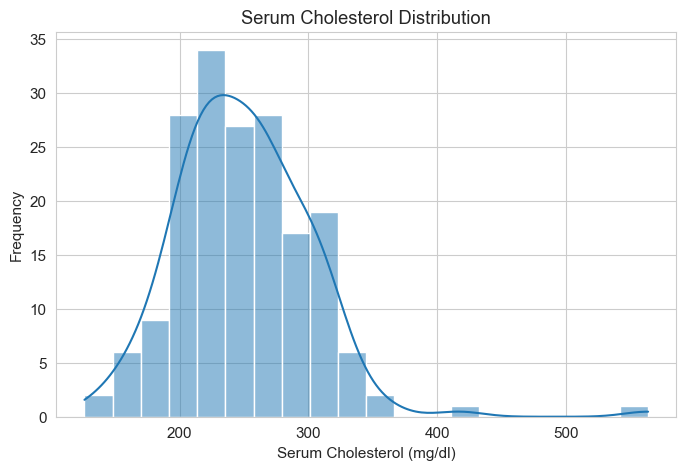

In [24]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='serum_cholesterol_mg_per_dl',
    bins=20,
    kde=True
)

plt.title('Serum Cholesterol Distribution')
plt.xlabel('Serum Cholesterol (mg/dl)')
plt.ylabel('Frequency')

plt.show()

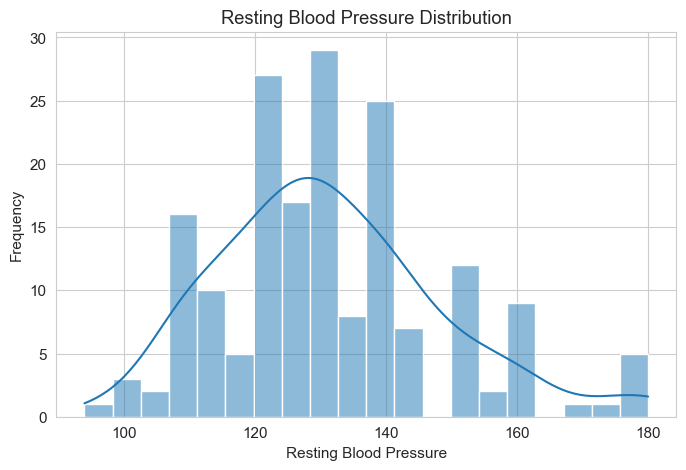

In [25]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='resting_blood_pressure',
    bins=20,
    kde=True
)

plt.title('Resting Blood Pressure Distribution')
plt.xlabel('Resting Blood Pressure')
plt.ylabel('Frequency')

plt.show()

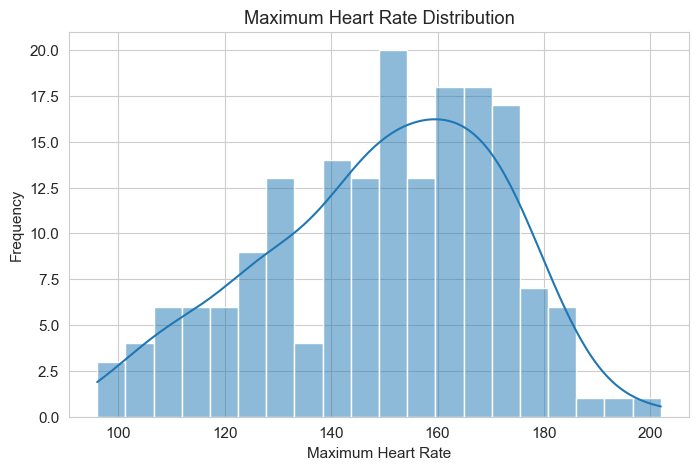

In [26]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='max_heart_rate_achieved',
    bins=20,
    kde=True
)

plt.title('Maximum Heart Rate Distribution')
plt.xlabel('Maximum Heart Rate')
plt.ylabel('Frequency')

plt.show()

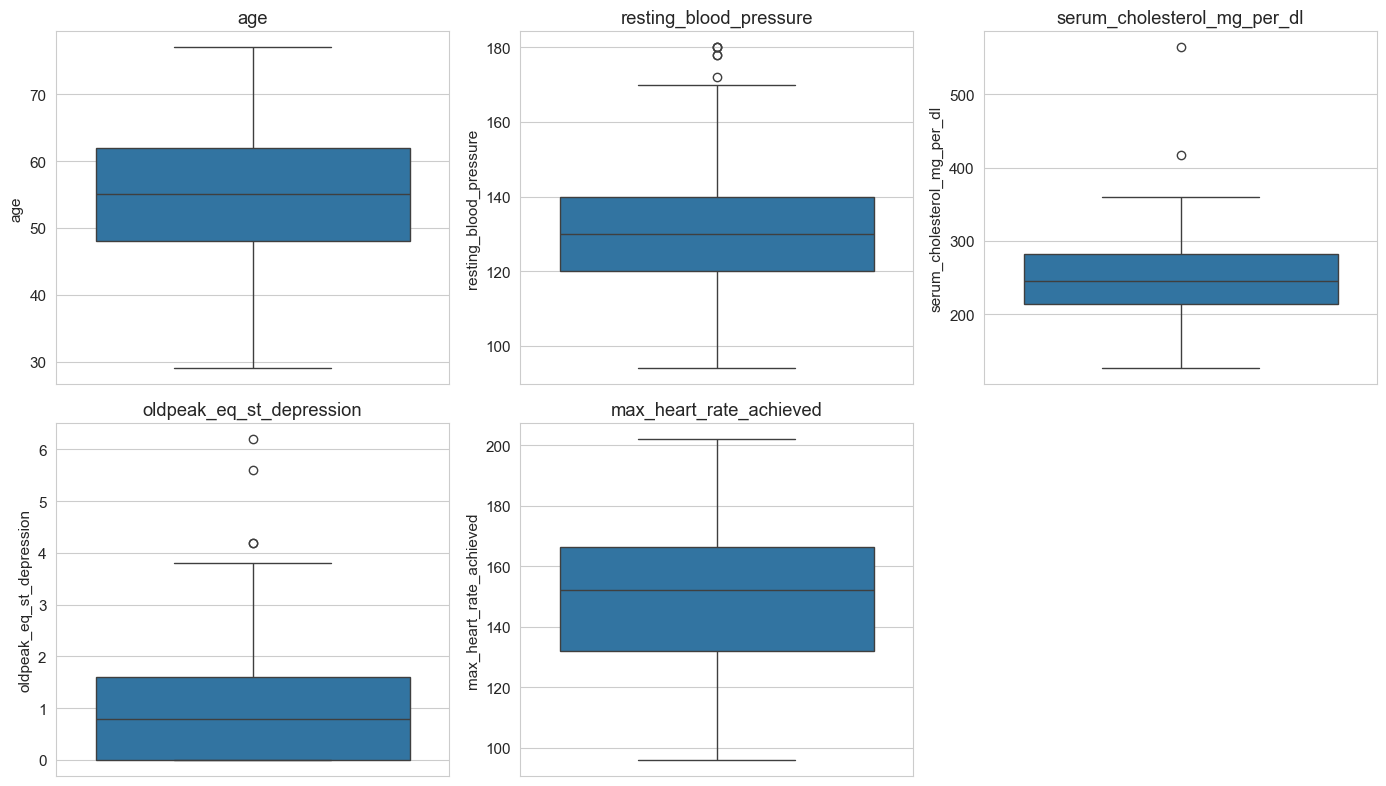

In [27]:
numerical_features = [
    'age',
    'resting_blood_pressure',
    'serum_cholesterol_mg_per_dl',
    'oldpeak_eq_st_depression',
    'max_heart_rate_achieved'
]

plt.figure(figsize=(14,8))

for i, col in enumerate(numerical_features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(data=df, y=col)
    plt.title(col)

plt.tight_layout()
plt.show()

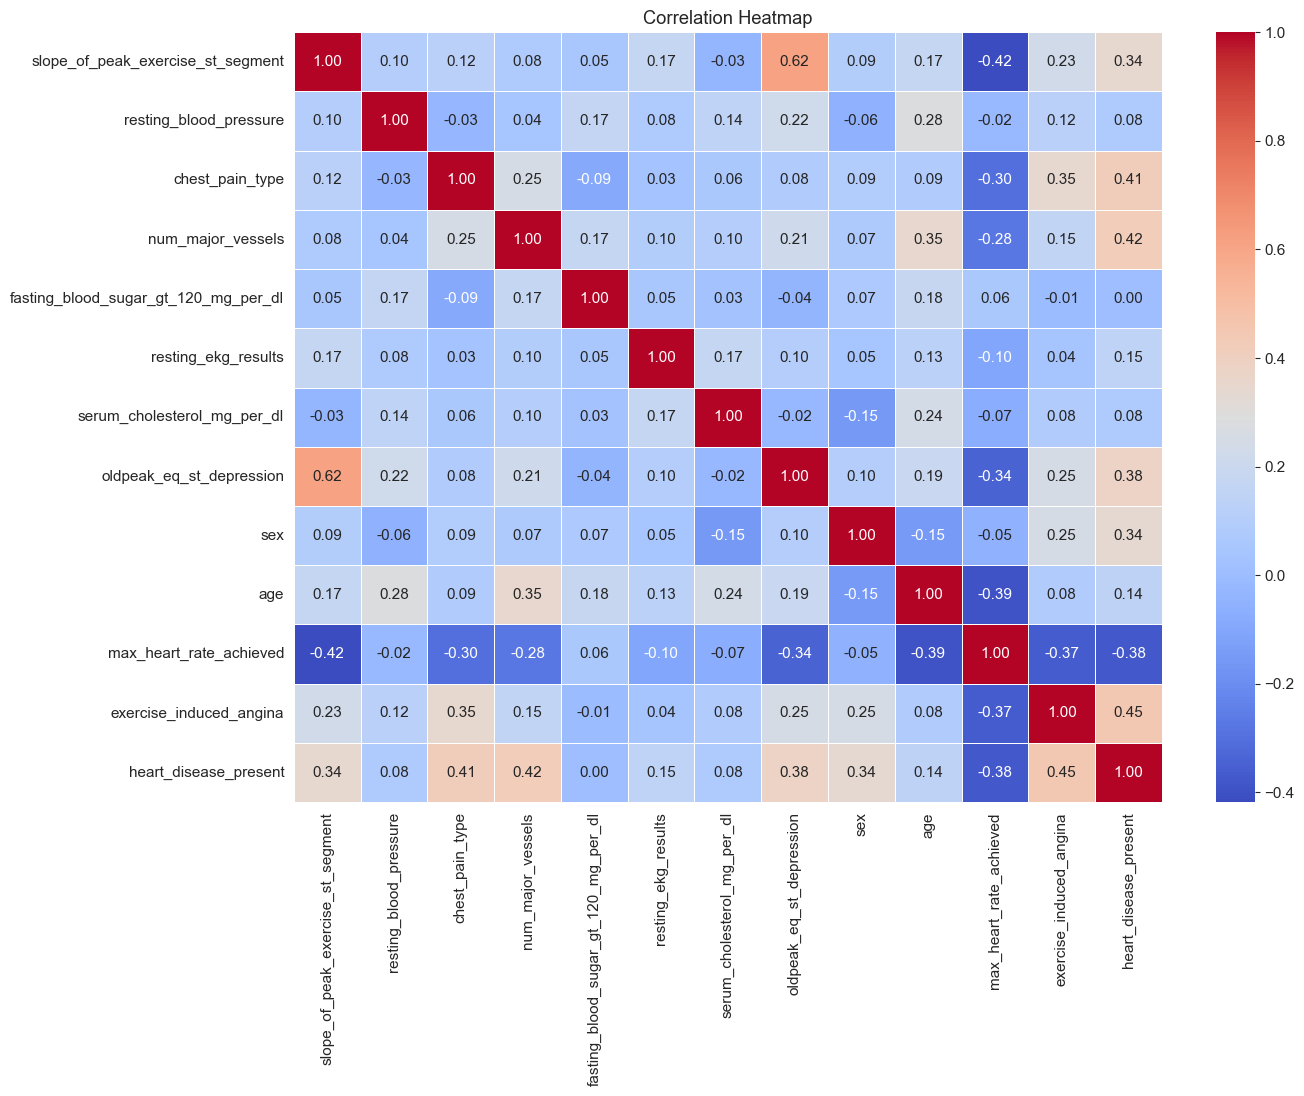

In [28]:
plt.figure(figsize=(14,10))

numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.drop(
    columns=['patient_id'],
    errors='ignore'
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')

plt.show()

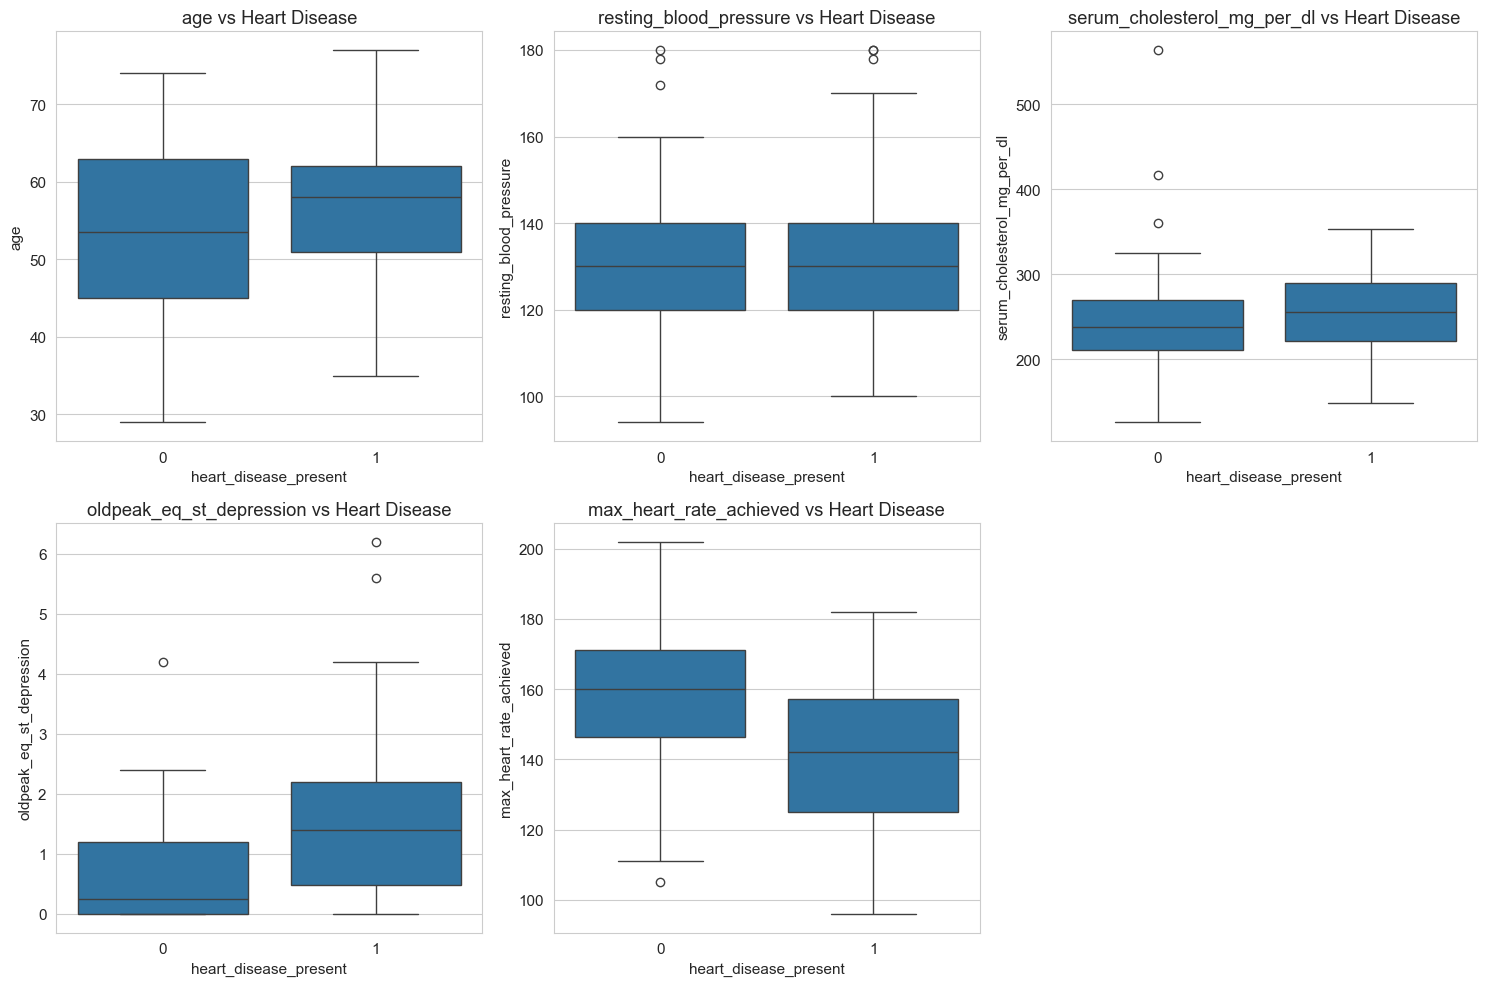

In [29]:
plt.figure(figsize=(15,10))

for i, col in enumerate(numerical_features, 1):

    plt.subplot(2, 3, i)

    sns.boxplot(
        data=df,
        x='heart_disease_present',
        y=col
    )

    plt.title(f'{col} vs Heart Disease')

plt.tight_layout()
plt.show()

## DATA PREPROCESSING

In [30]:
# Remove unnecessary ID column

# Create a copy of dataset
data = df.copy()

# Remove patient ID
data.drop('patient_id', axis=1, inplace=True)

print("Shape after removing ID:", data.shape)

data.head()

Shape after removing ID: (180, 14)


,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


In [31]:
# Separate features and target

X = data.drop('heart_disease_present', axis=1)

y = data['heart_disease_present']

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (180, 13)
Target Shape: (180,)


In [32]:
# Define categorical columns
categorical_cols = [
    'slope_of_peak_exercise_st_segment',
    'thal',
    'chest_pain_type',
    'num_major_vessels',
    'fasting_blood_sugar_gt_120_mg_per_dl',
    'resting_ekg_results',
    'sex',
    'exercise_induced_angina'
]

# Numerical columns
numerical_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

print("Categorical Features:")
print(categorical_cols)

print("\nNumerical Features:")
print(numerical_cols)

Categorical Features:
['slope_of_peak_exercise_st_segment', 'thal', 'chest_pain_type', 'num_major_vessels', 'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results', 'sex', 'exercise_induced_angina']

Numerical Features:
['resting_blood_pressure', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'age', 'max_heart_rate_achieved']


In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

Training Data: (144, 13)
Testing Data: (36, 13)
Training Target Distribution:
heart_disease_present
0    0.555556
1    0.444444
Name: proportion, dtype: float64

Testing Target Distribution:
heart_disease_present
0    0.555556
1    0.444444
Name: proportion, dtype: float64


In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

print("Preprocessing Pipeline Created Successfully!")

Preprocessing Pipeline Created Successfully!


In [35]:
# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data
X_test_processed = preprocessor.transform(X_test)

print("Training Data After Preprocessing:",
      X_train_processed.shape)

print("Testing Data After Preprocessing:",
      X_test_processed.shape)

Training Data After Preprocessing: (144, 27)
Testing Data After Preprocessing: (36, 27)


In [36]:
print("Target Distribution:")
print(y.value_counts())

print("\nTarget Percentage:")
print(y.value_counts(normalize=True) * 100)

Target Distribution:
heart_disease_present
0    100
1     80
Name: count, dtype: int64

Target Percentage:
heart_disease_present
0    55.555556
1    44.444444
Name: proportion, dtype: float64


In [37]:
print("PREPROCESSING SUMMARY")

print("Original Dataset:", df.shape)
print("Features after ID removal:", X.shape)
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

print("Missing Values in Training:",
      X_train.isnull().sum().sum())

print("Preprocessed Training Shape:",
      X_train_processed.shape)

print("Preprocessed Testing Shape:",
      X_test_processed.shape)

print("\nPreprocessing Completed!")

PREPROCESSING SUMMARY
Original Dataset: (180, 15)
Features after ID removal: (180, 13)
Training Samples: 144
Testing Samples: 36
Missing Values in Training: 0
Preprocessed Training Shape: (144, 27)
Preprocessed Testing Shape: (36, 27)

Preprocessing Completed!


### Data Preprocessing

Data preprocessing was performed to prepare the dataset for machine learning. The patient ID column was removed because it does not contribute meaningful predictive information. The independent and dependent variables were separated, and the dataset was divided into 80% training data and 20% testing data using stratified sampling.

Numerical features were processed using median imputation and StandardScaler. Categorical features were processed using most-frequent imputation and One-Hot Encoding. The preprocessing transformations were fitted only on the training data and applied to the testing data to prevent data leakage.

Class distribution was also examined to determine whether imbalance-handling techniques were necessary.

### FEATURE ENGINEERING & FEATURE SELECTION.

In [38]:
print("Total Features:", X.shape[1])

print("\nFeature Names:")
for col in X.columns:
    print(col)

Total Features: 13

Feature Names:
slope_of_peak_exercise_st_segment
thal
resting_blood_pressure
chest_pain_type
num_major_vessels
fasting_blood_sugar_gt_120_mg_per_dl
resting_ekg_results
serum_cholesterol_mg_per_dl
oldpeak_eq_st_depression
sex
age
max_heart_rate_achieved
exercise_induced_angina


In [39]:
from sklearn.feature_selection import SelectKBest, f_classif

# Select all features initially to calculate scores
selector = SelectKBest(score_func=f_classif, k='all')

selector.fit(X_train_processed, y_train)

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Create feature score dataframe
feature_scores = pd.DataFrame({
    'Feature': feature_names,
    'Score': selector.scores_,
    'P_Value': selector.pvalues_
})

# Sort by score
feature_scores = feature_scores.sort_values(
    by='Score',
    ascending=False
)

print(feature_scores)

                                        Feature      Score       P_Value
9                              cat__thal_normal  57.021135  4.784951e-12
10                  cat__thal_reversible_defect  52.406523  2.605393e-11
14                       cat__chest_pain_type_4  45.438304  3.658570e-10
25               cat__exercise_induced_angina_0  33.382129  4.600159e-08
26               cat__exercise_induced_angina_1  33.382129  4.600159e-08
15                     cat__num_major_vessels_0  25.909383  1.116302e-06
4                  num__max_heart_rate_achieved  23.591882  3.106626e-06
2                 num__oldpeak_eq_st_depression  19.914449  1.636540e-05
5      cat__slope_of_peak_exercise_st_segment_1  18.576531  3.032632e-05
24                                   cat__sex_1  16.227287  9.115229e-05
23                                   cat__sex_0  16.227287  9.115229e-05
13                       cat__chest_pain_type_3  12.312816  6.029786e-04
6      cat__slope_of_peak_exercise_st_segment_2  10

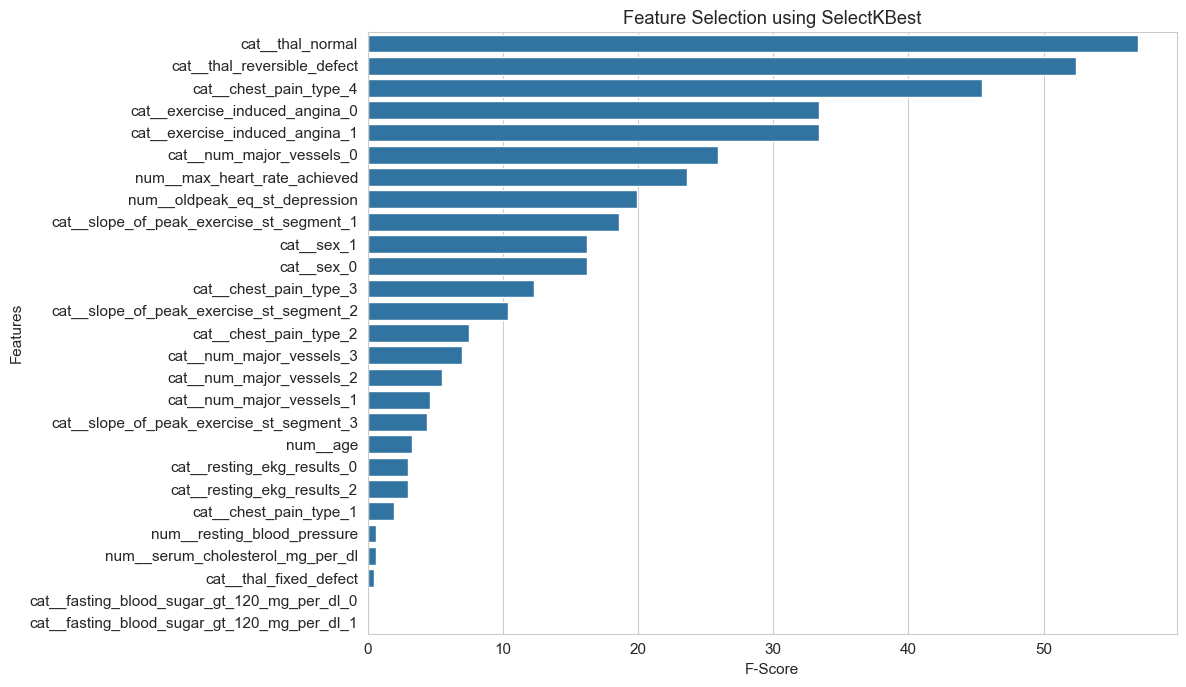

In [40]:
plt.figure(figsize=(12,7))

sns.barplot(
    data=feature_scores,
    x='Score',
    y='Feature'
)

plt.title('Feature Selection using SelectKBest')
plt.xlabel('F-Score')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

In [41]:
top_features = feature_scores.head(10)

print("Top 10 Features:")
print(top_features)

Top 10 Features:
                                     Feature      Score       P_Value
9                           cat__thal_normal  57.021135  4.784951e-12
10               cat__thal_reversible_defect  52.406523  2.605393e-11
14                    cat__chest_pain_type_4  45.438304  3.658570e-10
25            cat__exercise_induced_angina_0  33.382129  4.600159e-08
26            cat__exercise_induced_angina_1  33.382129  4.600159e-08
15                  cat__num_major_vessels_0  25.909383  1.116302e-06
4               num__max_heart_rate_achieved  23.591882  3.106626e-06
2              num__oldpeak_eq_st_depression  19.914449  1.636540e-05
5   cat__slope_of_peak_exercise_st_segment_1  18.576531  3.032632e-05
24                                cat__sex_1  16.227287  9.115229e-05


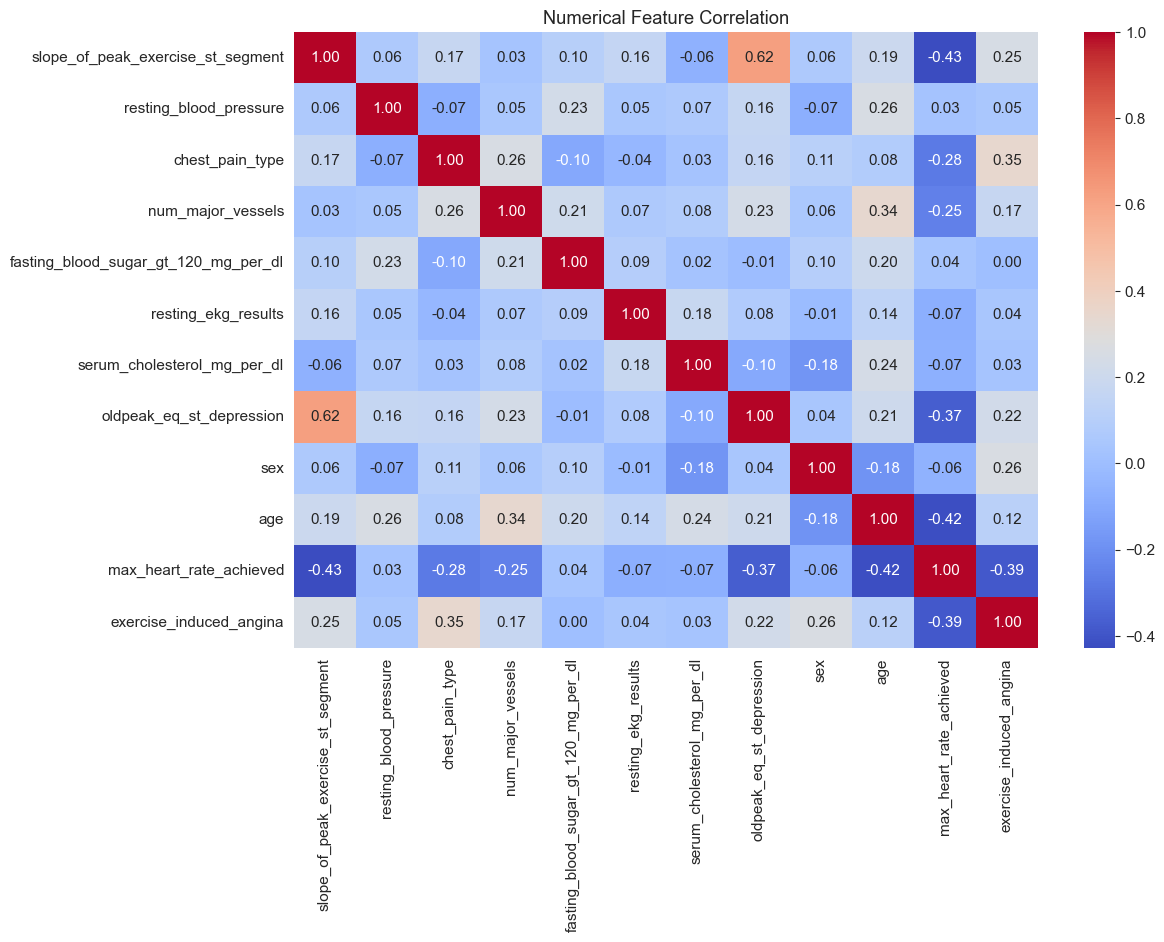

In [42]:
plt.figure(figsize=(12,8))

sns.heatmap(
    X_train.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Numerical Feature Correlation')
plt.show()

In [43]:
from sklearn.feature_selection import SelectKBest, f_classif

# Feature selection
selector = SelectKBest(
    score_func=f_classif,
    k='all'
)

selector.fit(X_train_processed, y_train)

# Get feature names
feature_names = preprocessor.get_feature_names_out()

# Create feature score dataframe
feature_scores = pd.DataFrame({
    'Feature': feature_names,
    'Score': selector.scores_,
    'P_Value': selector.pvalues_
})

# Sort feature scores
feature_scores = feature_scores.sort_values(
    by='Score',
    ascending=False
)

display(feature_scores)

,Feature,Score,P_Value
9,cat__thal_normal,57.021135,4.784951e-12
10,cat__thal_reversible_defect,52.406523,2.605393e-11
14,cat__chest_pain_type_4,45.438304,3.658570e-10
25,cat__exercise_induced_angina_0,33.382129,4.600159e-08
26,cat__exercise_induced_angina_1,33.382129,4.600159e-08
15,cat__num_major_vessels_0,25.909383,1.116302e-06
4,num__max_heart_rate_achieved,23.591882,3.106626e-06
2,num__oldpeak_eq_st_depression,19.914449,1.636540e-05
5,cat__slope_of_peak_exercise_st_segment_1,18.576531,3.032632e-05
24,cat__sex_1,16.227287,9.115229e-05


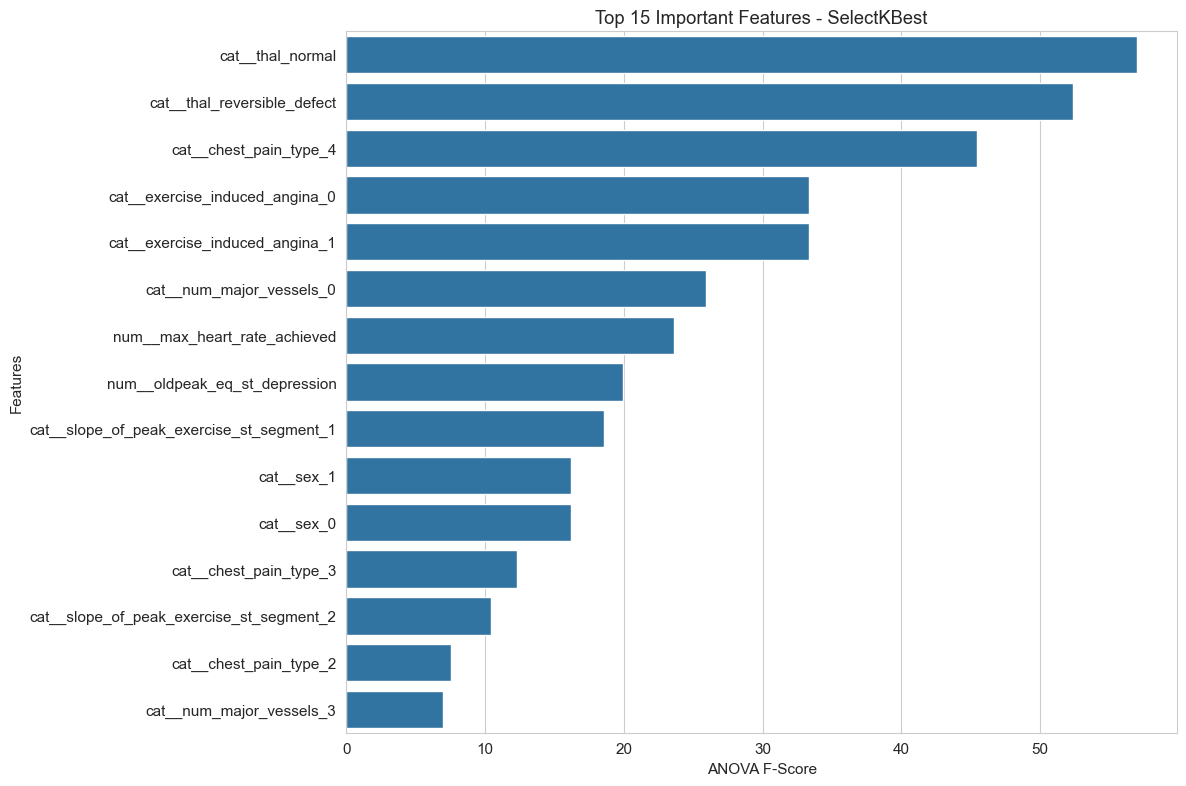

In [44]:
plt.figure(figsize=(12,8))

sns.barplot(
    data=feature_scores.head(15),
    x='Score',
    y='Feature'
)

plt.title('Top 15 Important Features - SelectKBest')
plt.xlabel('ANOVA F-Score')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

### Feature Engineering and Feature Selection - Report

Feature selection was performed to identify the most informative variables for heart disease prediction. The SelectKBest method with the ANOVA F-test was used to calculate feature scores using training data only.

The features were ranked according to their statistical association with the target variable. Correlation analysis was also performed to understand relationships among numerical variables.

The feature rankings were used for investigation and model interpretation. Final feature selection will be validated through cross-validation rather than assuming that the highest-scoring individual features always produce the best predictive model.

### MACHINE LEARNING MODEL BUILDING

In [45]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

print("All ML Algorithms Imported Successfully!")

All ML Algorithms Imported Successfully!


In [46]:
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42
    ),

    'SVM': SVC(
        probability=True,
        class_weight='balanced',
        random_state=42
    ),

    'XGBoost': XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.05,
        eval_metric='logloss',
        random_state=42
    )
}

print("5 Models Created Successfully!")

5 Models Created Successfully!


In [47]:
pipelines = {}

for name, model in models.items():

    pipelines[name] = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

print("All Model Pipelines Created Successfully!")

All Model Pipelines Created Successfully!


In [48]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'
}

results = []

for name, pipeline in pipelines.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1 Score': scores['test_f1'].mean(),
        'ROC AUC': scores['test_roc_auc'].mean(),
        'PR AUC': scores['test_pr_auc'].mean()
    })

model_results = pd.DataFrame(results)

model_results = model_results.sort_values(
    by='ROC AUC',
    ascending=False
)

display(model_results.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC
3,SVM,0.785,0.766,0.782,0.765,0.867,0.876
2,Random Forest,0.771,0.756,0.751,0.744,0.864,0.870
4,XGBoost,0.799,0.800,0.768,0.773,0.864,0.846
0,Logistic Regression,0.806,0.817,0.767,0.781,0.863,0.875
1,Decision Tree,0.743,0.697,0.750,0.719,0.744,0.639


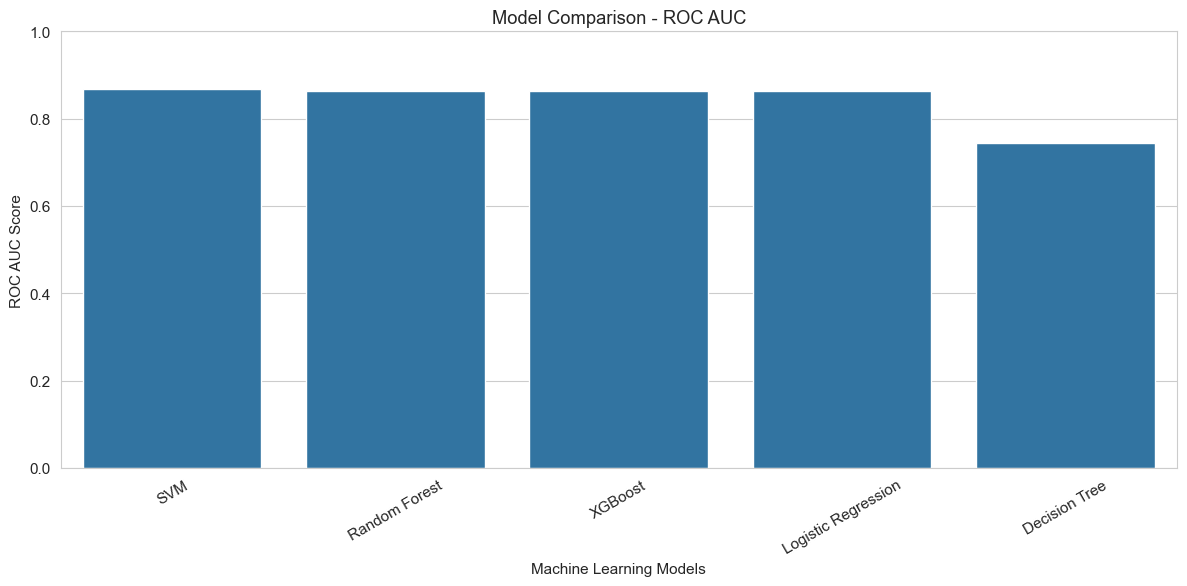

In [49]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=model_results,
    x='Model',
    y='ROC AUC'
)

plt.title('Model Comparison - ROC AUC')
plt.xlabel('Machine Learning Models')
plt.ylabel('ROC AUC Score')

plt.xticks(rotation=30)
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

 ### MODEL EVALUATION

In [50]:
# Select best model based on CV ROC-AUC
best_model_name = model_results.iloc[0]['Model']

print("Best Model:", best_model_name)

# Get selected pipeline
best_pipeline = pipelines[best_model_name]

# Train selected model
best_pipeline.fit(X_train, y_train)

print("Best Model Training Completed!")

Best Model: SVM
Best Model Training Completed!


In [51]:
# Predictions
y_pred = best_pipeline.predict(X_test)

# Prediction probabilities
y_prob = best_pipeline.predict_proba(X_test)[:, 1]

print("Predictions:", y_pred)
print("Actual Values:", y_test.values)

Predictions: [0 1 1 0 0 1 0 0 1 1 0 1 0 1 0 0 0 1 0 1 1 1 1 1 0 0 0 0 1 1 1 1 1 0 0 1]
Actual Values: [0 1 1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 1 0 1 1 1 1 1 0 0 0 0 1 0 1 1 1 0 0 0]


In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, zero_division=0)

recall = recall_score(y_test, y_pred, zero_division=0)

f1 = f1_score(y_test, y_pred, zero_division=0)

roc_auc = roc_auc_score(y_test, y_prob)

pr_auc = average_precision_score(y_test, y_prob)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print("Accuracy :", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall   :", round(recall, 3))
print("F1 Score :", round(f1, 3))
print("ROC-AUC  :", round(roc_auc, 3))
print("PR-AUC   :", round(pr_auc, 3))

MODEL EVALUATION RESULTS
------------------------
Accuracy : 0.917
Precision: 0.842
Recall   : 1.0
F1 Score : 0.914
ROC-AUC  : 0.966
PR-AUC   : 0.955


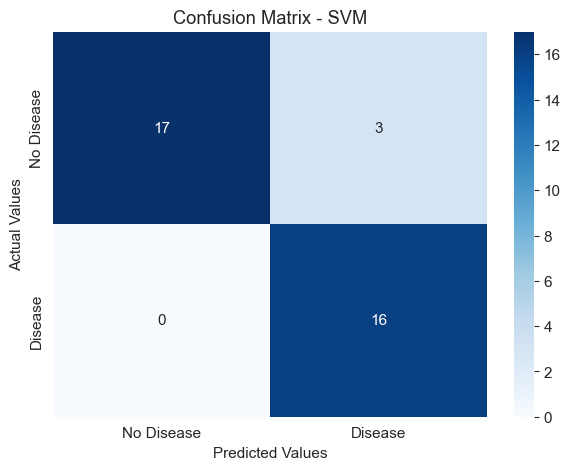

In [53]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Disease', 'Disease'],
    yticklabels=['No Disease', 'Disease']
)

plt.title('Confusion Matrix - ' + best_model_name)
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

In [54]:
from sklearn.metrics import classification_report

print("Classification Report")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=['No Disease', 'Disease'],
        zero_division=0
    )
)

Classification Report
              precision    recall  f1-score   support

  No Disease       1.00      0.85      0.92        20
     Disease       0.84      1.00      0.91        16

    accuracy                           0.92        36
   macro avg       0.92      0.93      0.92        36
weighted avg       0.93      0.92      0.92        36



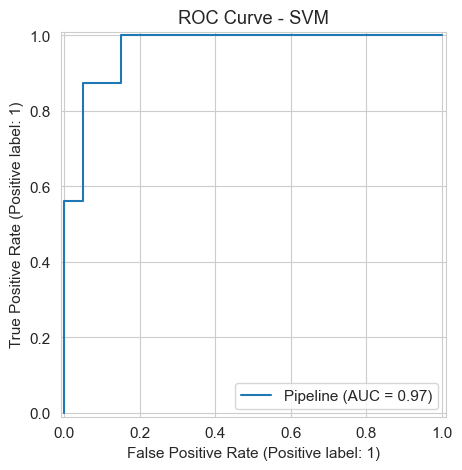

In [55]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(
    best_pipeline,
    X_test,
    y_test
)

plt.title('ROC Curve - ' + best_model_name)
plt.show()

### Model Evaluation - Report

Five machine learning algorithms were evaluated using stratified five-fold cross-validation. The models were compared using Accuracy, Precision, Recall, F1-score, ROC-AUC and PR-AUC.

The best-performing candidate was selected based on cross-validation ROC-AUC and subsequently evaluated on the independent test dataset.

A confusion matrix, classification report and ROC curve were generated to examine the classification performance. Recall was given particular attention because identifying potential heart disease cases is important in this healthcare prediction task.

The final model selection will also consider false-positive and false-negative predictions, model stability and the limitations of the small dataset.

### HYPERPARAMETER TUNING

In [56]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

In [57]:
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],

    'classifier__kernel': ['linear', 'rbf'],

    'classifier__gamma': ['scale', 'auto'],

    'classifier__class_weight': [None, 'balanced']
}

In [58]:
svm_pipeline = pipelines['SVM']

random_search = RandomizedSearchCV(
    estimator=svm_pipeline,
    param_distributions=param_grid,
    n_iter=20,
    scoring='roc_auc',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True
)

# Fit using training data only
random_search.fit(X_train, y_train)

print("Hyperparameter Tuning Completed!")

Hyperparameter Tuning Completed!


In [59]:
print("Best Parameters:")

print(random_search.best_params_)

print("\nBest Cross Validation ROC-AUC:")

print(round(random_search.best_score_, 3))

Best Parameters:
{'classifier__kernel': 'rbf', 'classifier__gamma': 'scale', 'classifier__class_weight': None, 'classifier__C': 0.1}

Best Cross Validation ROC-AUC:
0.876


In [60]:
best_svm_model = random_search.best_estimator_

print("Tuned SVM Model:")
print(best_svm_model)

Tuned SVM Model:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['resting_blood_pressure',
                                                   'serum_cholesterol_mg_per_dl',
                                                   'oldpeak_eq_st_depression',
                                                   'age',
                                                   'max_heart_rate_achieved']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                     

In [61]:
comparison = pd.DataFrame({
    'Model': [
        'Original SVM',
        'Tuned SVM'
    ],

    'CV ROC-AUC': [
        model_results.loc[
            model_results['Model'] == 'SVM',
            'ROC AUC'
        ].iloc[0],

        random_search.best_score_
    ]
})

display(comparison.round(3))

,Model,CV ROC-AUC
0,Original SVM,0.867
1,Tuned SVM,0.876


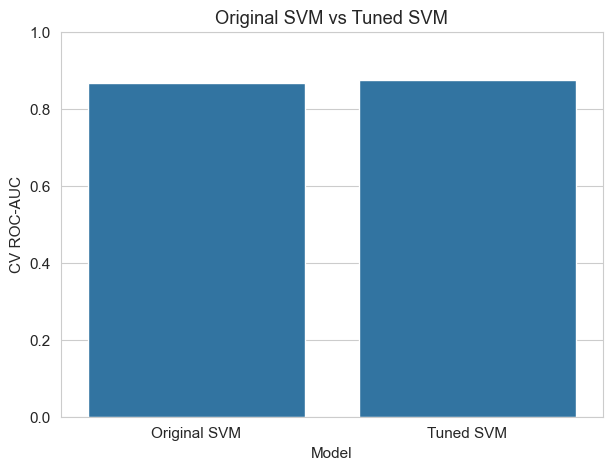

In [62]:
plt.figure(figsize=(7,5))

sns.barplot(
    data=comparison,
    x='Model',
    y='CV ROC-AUC'
)

plt.title('Original SVM vs Tuned SVM')
plt.ylim(0, 1)

plt.show()

### Hyperparameter Tuning

RandomizedSearchCV was used to optimize the Support Vector Machine model. The parameters C, kernel, gamma and class_weight were explored using stratified five-fold cross-validation.

ROC-AUC was selected as the optimization metric. The search was performed using training data only, with the complete preprocessing pipeline included to prevent data leakage.

The tuned model was compared against the original SVM using cross-validation ROC-AUC. The final model selection was based on predictive performance and stability rather than a single test-set score.

### FINAL MODEL EVALUATION

In [63]:
# Select tuned SVM model
final_model = best_svm_model

# Predict test data
y_pred_tuned = final_model.predict(X_test)

# Prediction probabilities
y_prob_tuned = final_model.predict_proba(X_test)[:, 1]

print("Tuned SVM Predictions:")
print(y_pred_tuned)

Tuned SVM Predictions:
[0 0 1 0 0 0 0 0 0 1 0 1 0 1 0 0 0 1 0 1 1 1 0 0 0 0 0 0 1 0 0 1 1 0 0 1]


In [64]:
from sklearn.metrics import *

final_accuracy = accuracy_score(y_test, y_pred_tuned)

final_precision = precision_score(
    y_test, y_pred_tuned, zero_division=0
)

final_recall = recall_score(
    y_test, y_pred_tuned, zero_division=0
)

final_f1 = f1_score(
    y_test, y_pred_tuned, zero_division=0
)

final_roc_auc = roc_auc_score(
    y_test, y_prob_tuned
)

final_pr_auc = average_precision_score(
    y_test, y_prob_tuned
)

print("FINAL TUNED SVM PERFORMANCE")
print("---------------------------")
print("Accuracy :", round(final_accuracy, 3))
print("Precision:", round(final_precision, 3))
print("Recall   :", round(final_recall, 3))
print("F1 Score :", round(final_f1, 3))
print("ROC-AUC  :", round(final_roc_auc, 3))
print("PR-AUC   :", round(final_pr_auc, 3))

FINAL TUNED SVM PERFORMANCE
---------------------------
Accuracy : 0.833
Precision: 0.917
Recall   : 0.688
F1 Score : 0.786
ROC-AUC  : 0.947
PR-AUC   : 0.931


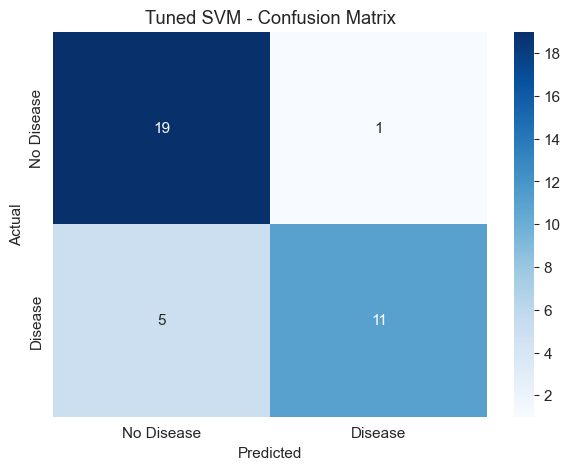

In [65]:
cm = confusion_matrix(y_test, y_pred_tuned)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Disease', 'Disease'],
    yticklabels=['No Disease', 'Disease']
)

plt.title('Tuned SVM - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [66]:
print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=['No Disease', 'Disease'],
    zero_division=0
))

              precision    recall  f1-score   support

  No Disease       0.79      0.95      0.86        20
     Disease       0.92      0.69      0.79        16

    accuracy                           0.83        36
   macro avg       0.85      0.82      0.82        36
weighted avg       0.85      0.83      0.83        36



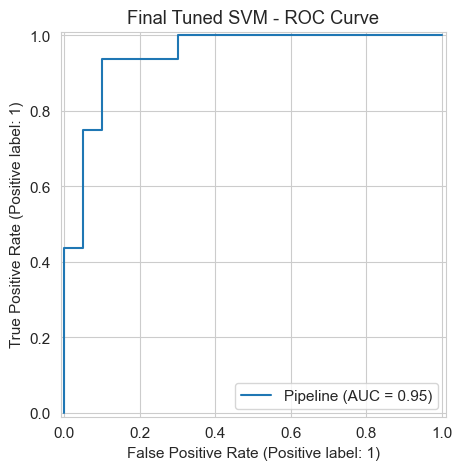

In [67]:
RocCurveDisplay.from_estimator(
    final_model,
    X_test,
    y_test
)

plt.title('Final Tuned SVM - ROC Curve')
plt.show()

In [68]:
original_svm = pipelines['SVM']

original_svm.fit(X_train, y_train)

original_pred = original_svm.predict(X_test)
original_prob = original_svm.predict_proba(X_test)[:, 1]

comparison_final = pd.DataFrame({
    'Model': ['Original SVM', 'Tuned SVM'],

    'Accuracy': [
        accuracy_score(y_test, original_pred),
        accuracy_score(y_test, y_pred_tuned)
    ],

    'Precision': [
        precision_score(y_test, original_pred, zero_division=0),
        precision_score(y_test, y_pred_tuned, zero_division=0)
    ],

    'Recall': [
        recall_score(y_test, original_pred, zero_division=0),
        recall_score(y_test, y_pred_tuned, zero_division=0)
    ],

    'F1 Score': [
        f1_score(y_test, original_pred, zero_division=0),
        f1_score(y_test, y_pred_tuned, zero_division=0)
    ],

    'ROC-AUC': [
        roc_auc_score(y_test, original_prob),
        roc_auc_score(y_test, y_prob_tuned)
    ]
})

display(comparison_final.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Original SVM,0.917,0.842,1.000,0.914,0.966
1,Tuned SVM,0.833,0.917,0.688,0.786,0.947


### Final Model Evaluation

The tuned Support Vector Machine model was evaluated using the independent test dataset. Accuracy, Precision, Recall, F1-score, ROC-AUC and PR-AUC were calculated to assess its predictive performance.

A confusion matrix and classification report were generated to understand correct and incorrect predictions. The tuned model was also compared with the original SVM model to assess the improvement obtained through hyperparameter optimization.

The final model's suitability was considered based on its overall performance, ability to identify positive cases, and the balance between false positives and false negatives.

### Original SVM vs Tuned SVM Comparison

The original SVM achieved an accuracy of 91.7%, precision of 84.2%, recall of 100%, F1-score of 91.4%, and ROC-AUC of 0.966 on the test dataset.

The tuned SVM achieved an accuracy of 83.3%, precision of 91.7%, recall of 68.8%, F1-score of 78.6%, and ROC-AUC of 0.947.

Although hyperparameter tuning slightly improved cross-validation ROC-AUC, the tuned model did not improve performance on the independent test dataset. The original SVM showed better test recall and overall test performance, while the tuned SVM demonstrated higher precision.

Therefore, the original SVM is the provisional preferred candidate based on the current test results. Further validation is required before making a final clinical suitability claim.

### THRESHOLD ANALYSIS

In [70]:
from sklearn.model_selection import cross_val_predict

# Original SVM pipeline
original_svm = pipelines['SVM']

# Out-of-fold probabilities using training data
oof_prob = cross_val_predict(
    original_svm,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

print("Cross-validation probabilities generated!")

Cross-validation probabilities generated!


In [71]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:

    predictions = (oof_prob >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            y_train, predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_train, predictions, zero_division=0
        ),
        'F1 Score': f1_score(
            y_train, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))

,Threshold,Precision,Recall,F1 Score
0,0.3,0.659,0.844,0.740
1,0.4,0.693,0.812,0.748
2,0.5,0.778,0.766,0.772
3,0.6,0.782,0.672,0.723
4,0.7,0.867,0.609,0.716


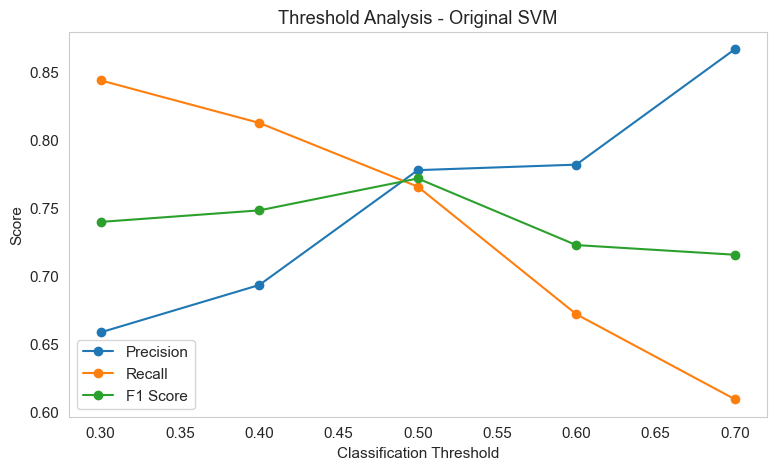

In [72]:
plt.figure(figsize=(9,5))

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['F1 Score'],
    marker='o',
    label='F1 Score'
)

plt.title('Threshold Analysis - Original SVM')
plt.xlabel('Classification Threshold')
plt.ylabel('Score')

plt.legend()
plt.grid()
plt.show()

### MODEL INTERPRETATION

In [73]:
from sklearn.inspection import permutation_importance

# Fit original SVM on training data
original_svm.fit(X_train, y_train)

# Calculate permutation importance
perm_result = permutation_importance(
    original_svm,
    X_test,
    y_test,
    scoring='roc_auc',
    n_repeats=30,
    random_state=42
)

# Create feature importance dataframe
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': perm_result.importances_mean,
    'Std': perm_result.importances_std
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

display(importance_df)

,Feature,Importance,Std
1,thal,0.063750,0.024759
8,oldpeak_eq_st_depression,0.040312,0.014732
4,num_major_vessels,0.039167,0.010787
3,chest_pain_type,0.035625,0.020597
0,slope_of_peak_exercise_st_segment,0.027917,0.008688
12,exercise_induced_angina,0.018958,0.011466
2,resting_blood_pressure,0.015937,0.008242
9,sex,0.011042,0.011460
11,max_heart_rate_achieved,0.007500,0.008898
7,serum_cholesterol_mg_per_dl,0.005208,0.006002


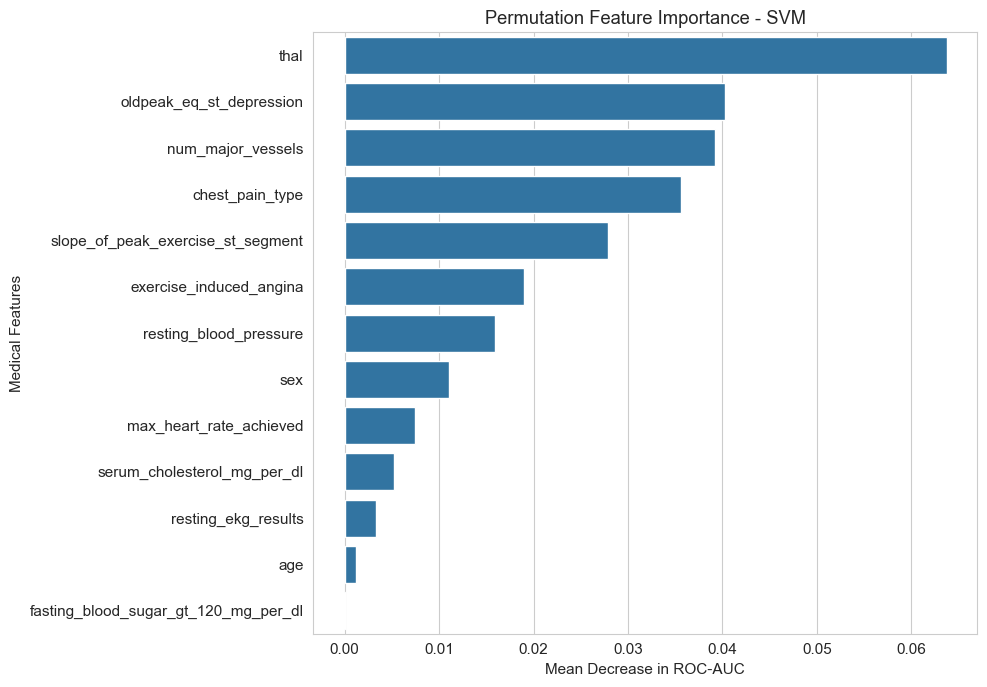

In [74]:
plt.figure(figsize=(10,7))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title('Permutation Feature Importance - SVM')
plt.xlabel('Mean Decrease in ROC-AUC')
plt.ylabel('Medical Features')

plt.tight_layout()
plt.show()

### Model Interpretation

Permutation importance was used to investigate the contribution of individual input features to the SVM model's predictive performance. Each feature was randomly shuffled, and the resulting change in ROC-AUC was measured.

Features producing larger decreases in ROC-AUC were considered more influential for the model's predictions. This analysis provides an interpretation of model behaviour, but it does not establish medical causation or clinical importance.

The results should be interpreted cautiously because the dataset contains only 180 patient records.

### SAVE FINAL MACHINE LEARNING MODEL

In [75]:
final_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', models['SVM'])
])

final_model.fit(X_train, y_train)

print("Final model trained successfully!")

Final model trained successfully!


In [76]:
import joblib

joblib.dump(
    final_model,
    'heart_disease_prediction_model.pkl'
)

print("Model saved successfully!")

Model saved successfully!


In [77]:
loaded_model = joblib.load(
    'heart_disease_prediction_model.pkl'
)

print("Model loaded successfully!")

Model loaded successfully!


In [78]:
saved_predictions = loaded_model.predict(X_test)

print("Original predictions:")
print(final_model.predict(X_test))

print("\nLoaded model predictions:")
print(saved_predictions)

print(
    "\nPredictions Match:",
    np.array_equal(
        final_model.predict(X_test),
        saved_predictions
    )
)

Original predictions:
[0 1 1 0 0 1 0 0 1 1 0 1 0 1 0 0 0 1 0 1 1 1 1 1 0 0 0 0 1 1 1 1 1 0 0 1]

Loaded model predictions:
[0 1 1 0 0 1 0 0 1 1 0 1 0 1 0 0 0 1 0 1 1 1 1 1 0 0 0 0 1 1 1 1 1 0 0 1]

Predictions Match: True


### HOSPITAL RECOMMENDATIONS & BUSINESS INSIGHTS

In [79]:
# Group patients based on heart disease status

disease_comparison = data.groupby(
    'heart_disease_present'
)[numerical_cols].agg(
    ['mean', 'median', 'std']
)

display(disease_comparison.round(2))

resting_blood_pressure                \
                                        mean median    std   
heart_disease_present                                        
0                                     130.12  130.0  17.04   
1                                     132.80  130.0  16.96   

                      serum_cholesterol_mg_per_dl                \
                                             mean median    std   
heart_disease_present                                             
0                                          245.46  237.5  57.01   
1                                          253.90  255.5  46.73   

                      oldpeak_eq_st_depression                 age         \
                                          mean median   std   mean median   
heart_disease_present                                                       
0                                         0.63   0.25  0.79  53.66   53.5   
1                                         1.49   1.40  1.29  56.25   58.0   

                            max_heart_rate_achieved                
                        std                    mean median    std  
heart_disease_present                                              
0                      9.76                  156.87  160.0  19.09  
1                      8.62                  140.25  142.0  22.16

In [80]:
for col in categorical_cols:

    print("\nFeature:", col)

    result = pd.crosstab(
        data[col],
        data['heart_disease_present'],
        normalize='columns'
    ) * 100

    display(result.round(2))


Feature: slope_of_peak_exercise_st_segment


heart_disease_present,0,1
slope_of_peak_exercise_st_segment,,
1,68.0,31.25
2,28.0,58.75
3,4.0,10.00



Feature: thal


heart_disease_present,0,1
thal,,
fixed_defect,4.0,5.0
normal,78.0,25.0
reversible_defect,18.0,70.0



Feature: chest_pain_type


heart_disease_present,0,1
chest_pain_type,,
1,9.0,5.00
2,24.0,5.00
3,44.0,16.25
4,23.0,73.75


... (6 outputs left out)


Feature: sex


heart_disease_present,0,1
sex,,
0,45.0,13.75
1,55.0,86.25



Feature: exercise_induced_angina


heart_disease_present,0,1
exercise_induced_angina,,
0,87.0,45.0
1,13.0,55.0


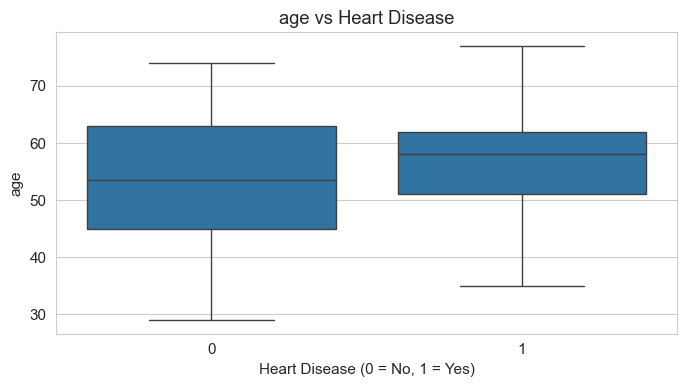

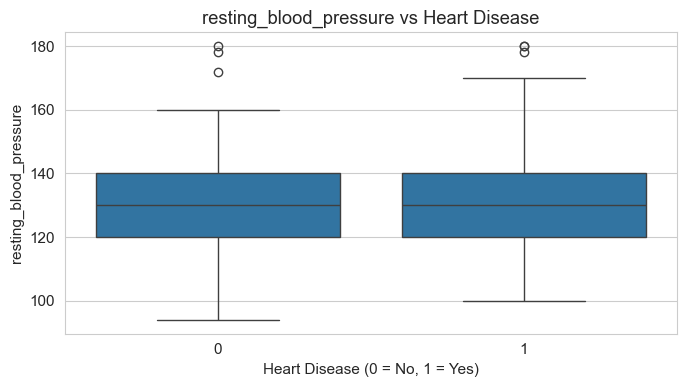

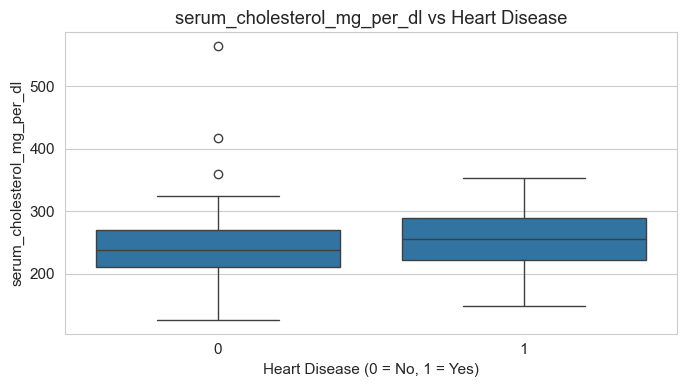

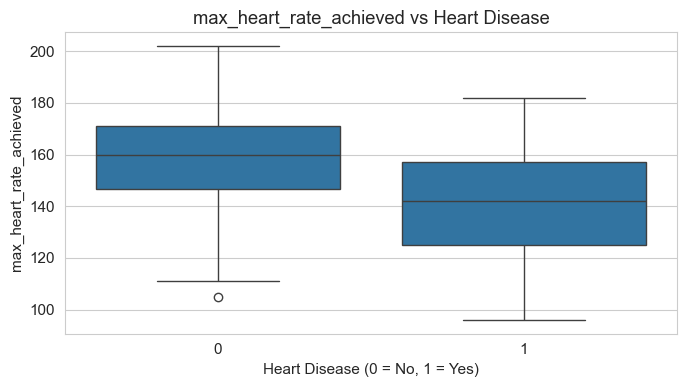

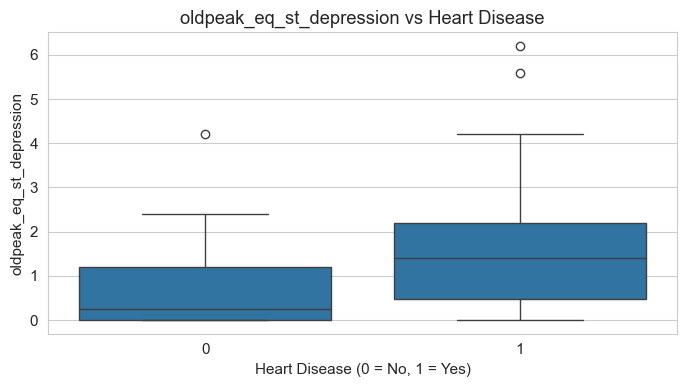

In [81]:
important_features = [
    'age',
    'resting_blood_pressure',
    'serum_cholesterol_mg_per_dl',
    'max_heart_rate_achieved',
    'oldpeak_eq_st_depression'
]

for col in important_features:

    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=data,
        x='heart_disease_present',
        y=col
    )

    plt.title(f'{col} vs Heart Disease')
    plt.xlabel('Heart Disease (0 = No, 1 = Yes)')
    plt.ylabel(col)

    plt.tight_layout()
    plt.show()

# Hospital Recommendations and Business Insights

Based on the exploratory data analysis and machine learning results, the following recommendations are proposed for hospitals:

1. **Early Screening:** Hospitals should encourage regular cardiovascular health assessments to identify potential risk indicators at an early stage.

2. **Blood Pressure Monitoring:** Regular monitoring of resting blood pressure can help healthcare professionals identify patients who may require further evaluation.

3. **Cholesterol Monitoring:** Periodic cholesterol testing and appropriate medical follow-up should be encouraged.

4. **Patient Monitoring:** Clinical indicators such as age, chest pain type, exercise-induced angina, maximum heart rate and ST depression can be considered during patient assessment.

5. **Data-Driven Healthcare:** Machine learning models may be evaluated as supplementary tools to support preliminary risk assessment, subject to clinical validation.

6. **Regular Health Check-ups:** Hospitals should promote preventive healthcare awareness and routine cardiovascular examinations.

7. **Model Validation:** Before practical implementation, the prediction model must be tested using larger, representative patient datasets and independently validated by healthcare professionals.

These recommendations aim to support early assessment, preventive healthcare and data-driven hospital decision-making. The model is an educational research prototype and must not replace professional medical diagnosis.

In [82]:
# Compare numerical features by target

summary = data.groupby(
    'heart_disease_present'
)[numerical_cols].mean().T

summary.columns = [
    'No Heart Disease',
    'Heart Disease'
]

summary['Difference'] = (
    summary['Heart Disease'] -
    summary['No Heart Disease']
)

display(summary.round(2))

,No Heart Disease,Heart Disease,Difference
resting_blood_pressure,130.12,132.80,2.68
serum_cholesterol_mg_per_dl,245.46,253.90,8.44
oldpeak_eq_st_depression,0.63,1.49,0.86
age,53.66,56.25,2.59
max_heart_rate_achieved,156.87,140.25,-16.62


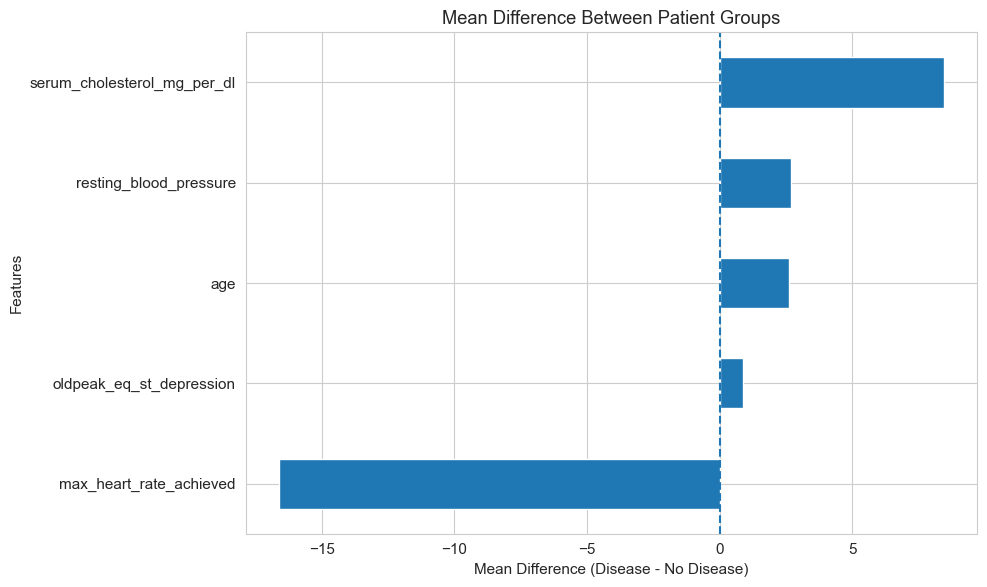

In [83]:
plt.figure(figsize=(10,6))

summary['Difference'].sort_values().plot(
    kind='barh'
)

plt.axvline(0, linestyle='--')

plt.title('Mean Difference Between Patient Groups')
plt.xlabel('Mean Difference (Disease - No Disease)')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

## 15. Limitations and Future Scope

### Limitations

1. The dataset contains only 180 patient records, limiting the generalizability of the findings.
2. Model performance may vary with different train-test splits.
3. The analysis is based on the available medical features.
4. External validation using independent hospital datasets has not been performed.
5. Hyperparameter tuning did not improve all test evaluation metrics.
6. Statistical associations do not establish causal relationships.

### Future Scope

1. Collect larger and more diverse patient datasets.
2. Validate the model using independent hospital data.
3. Explore additional clinically relevant features.
4. Perform more extensive cross-validation.
5. Investigate probability calibration and classification threshold optimization.
6. Evaluate model performance across different patient populations.

These improvements can help assess the reliability and potential applicability of the model in future healthcare research.

# Final Conclusion

The Heart Disease Prediction project was conducted to analyse cardiovascular patient data and develop a machine learning classification model.

The project included data understanding, exploratory data analysis, data preprocessing, statistical analysis, feature selection, model development, hyperparameter optimization and model evaluation.

Five classification algorithms were compared: Support Vector Machine, Random Forest, XGBoost, Logistic Regression and Decision Tree.

Among the evaluated models, the original Support Vector Machine achieved the best observed test performance, with:

- Accuracy: 91.7%
- Precision: 84.2%
- Recall: 100%
- F1-score: 91.4%
- ROC-AUC: 0.966

The tuned SVM achieved a test accuracy of 83.3% and ROC-AUC of 0.947. Therefore, hyperparameter tuning did not improve the final test performance in this experiment.

The analysis also identified differences in medical feature distributions between patients with and without heart disease.

The project demonstrates how data science and machine learning techniques can support cardiovascular data analysis and preliminary risk assessment.

However, the dataset contains only 180 records. Therefore, larger datasets, independent clinical validation and further evaluation are necessary before considering real-world healthcare applications.

Overall, this project demonstrates an end-to-end data science workflow for heart disease prediction and provides analytical insights that may support future healthcare research.

In [84]:
import joblib
import os

os.makedirs("Heart_Disease_Prediction", exist_ok=True)

joblib.dump(
    final_model,
    "Heart_Disease_Prediction/heart_disease_prediction_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!
